# Iris Flower Classification
## Oasis Infobyte — Data Science Internship, Project 1
**Intern:** Sumit Kumar  
**Course:** B.Tech Computer Science

### Project goal
Use four flower measurements to predict one of three Iris species: **setosa**, **versicolor**, or **virginica**. This is **classification** because the answer is a category, not a number.

### Our step-by-step plan
1. Load and inspect the built-in Iris dataset.
2. Explore the measurements and species using tables and plots.
3. Split the data into training and testing sets.
4. Train Logistic Regression and Decision Tree models.
5. Evaluate and compare both models on the same test data.
6. Write conclusions from the outputs and prepare a README.

Each major step has an explanation followed by a focused code cell. All reported results will come from executed code.

## 1. Import the libraries
- **pandas** organizes the data into tables.
- **matplotlib** and **seaborn** draw graphs.
- **scikit-learn** supplies the dataset, models, and evaluation tools.

We also check library versions and the working folder. These help make the project easier to reproduce.

In [16]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_fscore_support, classification_report
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

versions = pd.Series({
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scikit-learn": sklearn.__version__
}, name="Version")
display(versions.to_frame())
print("Kernel working folder:", Path.cwd())

,Version
Python,3.14.6
pandas,3.0.3
matplotlib,3.11.0
seaborn,0.13.2
scikit-learn,1.9.0


Kernel working folder: C:\Users\sumit\Jupyter folder\OIBSIP_INTERNSHIP


## 2. Load the Iris dataset
`load_iris()` provides four measurements in **centimetres** for each flower:
- Sepal length and sepal width: measurements of the outer leaf-like parts.
- Petal length and petal width: measurements of the petals.

The numeric target codes represent species. We add a readable `species` column for exploration. Later, the models will use **only the four measurements** as inputs—not the species label.

In [17]:
iris = load_iris()
feature_names = list(iris.feature_names)
species_names = list(iris.target_names)

X = pd.DataFrame(iris.data, columns=feature_names)
y = pd.Series(iris.target, name="target")
df = X.copy()
df["species"] = y.map(dict(enumerate(species_names)))

print("Species codes:", dict(enumerate(species_names)))
display(df.head())

Species codes: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Inspect the data
Before training, check the number of rows and columns, column names, data types, and missing values. `describe()` reports the count, mean, standard deviation (spread), minimum, quartiles, and maximum of each numeric feature. Quartiles divide the sorted values into four parts.

The feature table `X` contains measurements only. The exploration table `df` also contains the species label.

In [18]:
print("Feature table shape (rows, columns):", X.shape)
print("Exploration table shape (rows, columns):", df.shape)
print("Column names:", df.columns.tolist())

display(pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum()
}))
display(X.describe().round(3))
display(df["species"].value_counts().reindex(species_names).rename("Flower count").to_frame())

Feature table shape (rows, columns): (150, 4)
Exploration table shape (rows, columns): (150, 5)
Column names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']


,Data type,Missing values
sepal length (cm),float64,0
sepal width (cm),float64,0
petal length (cm),float64,0
petal width (cm),float64,0
species,str,0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


,Flower count
species,
setosa,50
versicolor,50
virginica,50


## 4. Exploratory Data Analysis (EDA)
EDA means exploring the data before building models. We ask: Are the species balanced? Which measurements differ between species? Which groups overlap?

**Inspection results:** There are **150 flowers**, **four numeric features**, and **no missing values**. The exploration table has five columns because it includes `species`. Each species has **50 flowers**, so the classes are balanced. No missing-value filling is needed.

### 4.1 Species counts and average measurements
The count chart shows class balance. Group averages give a first idea of how the measurements differ. Averages alone do not show overlap, so we will also look at individual points and distributions.

This full-dataset EDA is descriptive. We will keep the test set out of model fitting and scaling, and we will not tune models using test results.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


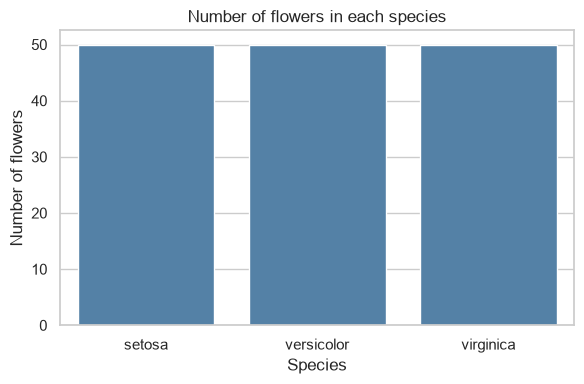

In [19]:
species_means = df.groupby("species")[feature_names].mean().reindex(species_names)
display(species_means.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="species", order=species_names, color="steelblue", ax=ax)
ax.set_title("Number of flowers in each species")
ax.set_xlabel("Species")
ax.set_ylabel("Number of flowers")
plt.tight_layout()
plt.show()

### 4.2 Pairplot: compare all feature pairs
A **pairplot** shows a scatter plot for each pair of measurements. Every point represents one flower, and the colour identifies its species. The diagonal histograms show the distribution of each measurement.

Look for separate colour groups: clearer separation means those features may be useful for classification. Mixed colours indicate overlap.

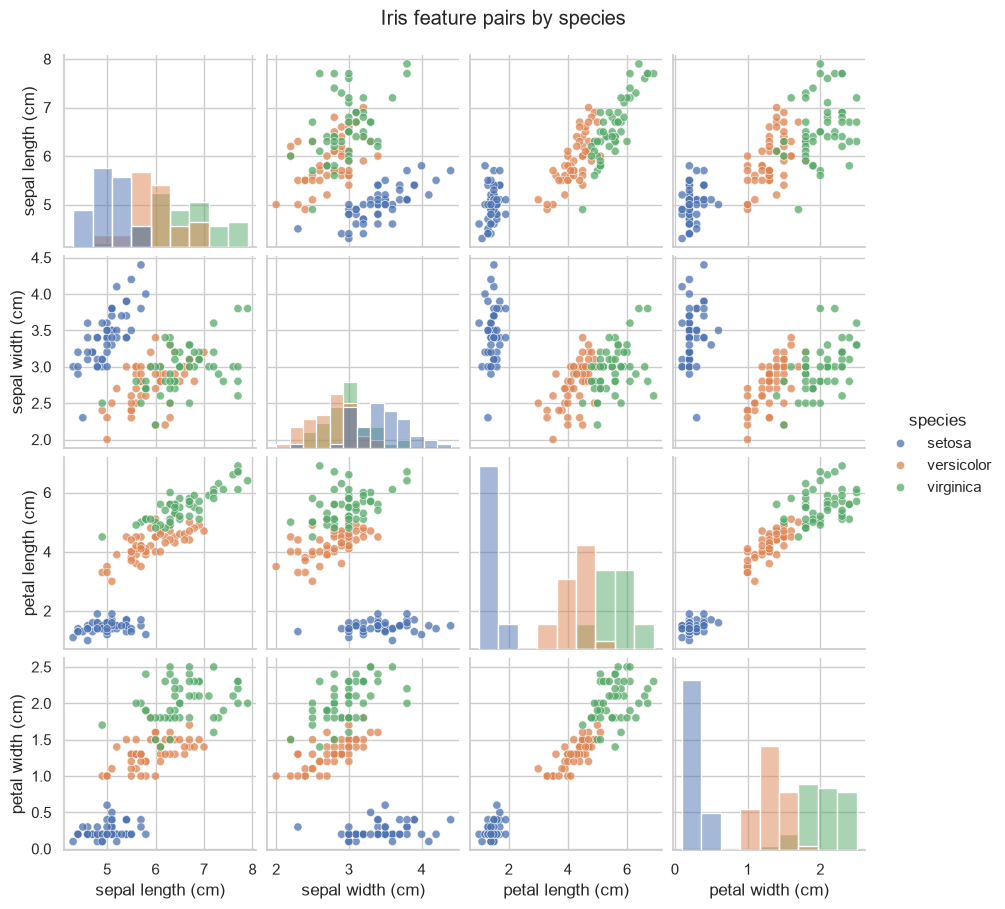

In [20]:
pair_grid = sns.pairplot(
    data=df, vars=feature_names, hue="species", hue_order=species_names,
    diag_kind="hist", height=2.2,
    plot_kws={"alpha": 0.75, "s": 35}
)
pair_grid.fig.suptitle("Iris feature pairs by species", y=1.03)
plt.show()

### 4.3 Feature-wise boxplots
We draw one boxplot for each of the four features, grouped by species.
- The line inside a box is the **median** (middle value).
- The box contains the middle **50%** of measurements.
- Whiskers show values within 1.5 times the box's range; points beyond them are possible outliers, not automatically mistakes.

Separated boxes suggest useful features. Overlapping boxes suggest that a single measurement may not be enough. The table also shows each species' minimum, median, and maximum.

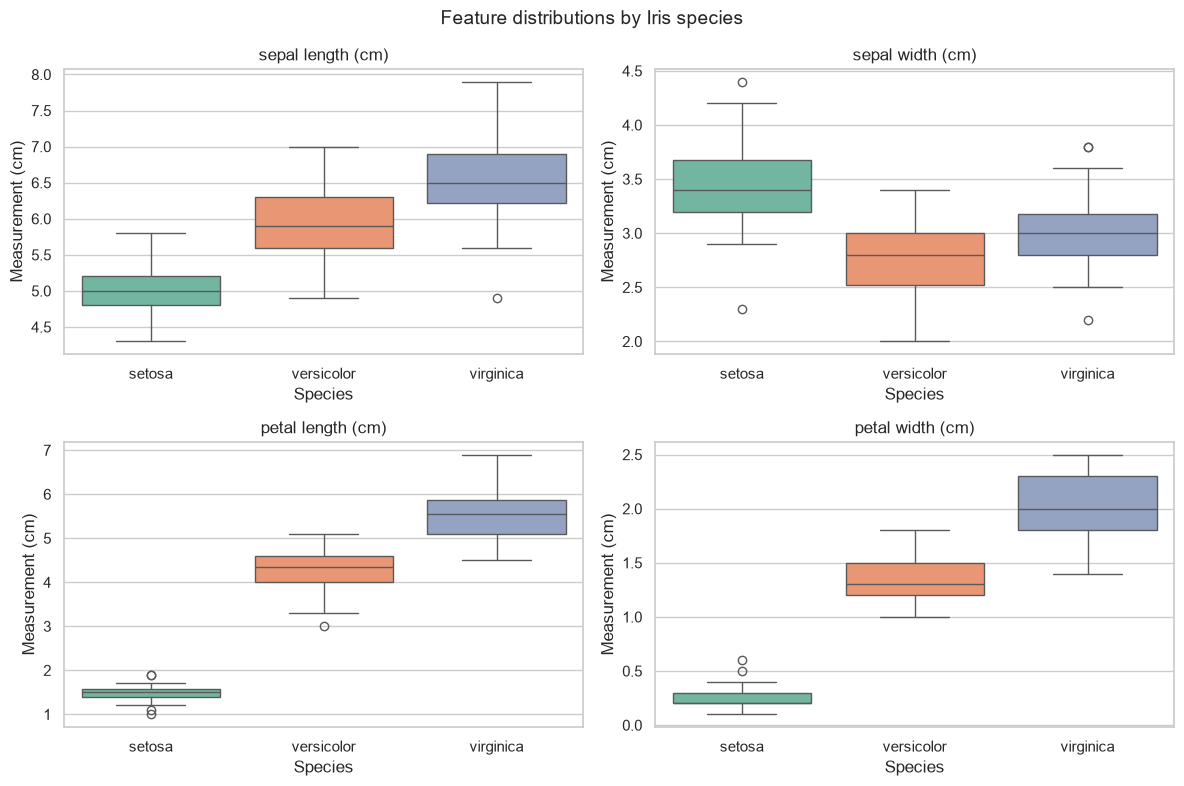

sepal length (cm)             sepal width (cm)              \
                         min median  max              min median  max   
species                                                                 
setosa                   4.3    5.0  5.8              2.3    3.4  4.4   
versicolor               4.9    5.9  7.0              2.0    2.8  3.4   
virginica                4.9    6.5  7.9              2.2    3.0  3.8   

           petal length (cm)             petal width (cm)              
                         min median  max              min median  max  
species                                                                
setosa                   1.0   1.50  1.9              0.1    0.2  0.6  
versicolor               3.0   4.35  5.1              1.0    1.3  1.8  
virginica                4.5   5.55  6.9              1.4    2.0  2.5

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, feature_names):
    sns.boxplot(
        data=df, x="species", y=feature, hue="species",
        order=species_names, hue_order=species_names,
        palette="Set2", legend=False, ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Species")
    ax.set_ylabel("Measurement (cm)")
fig.suptitle("Feature distributions by Iris species", fontsize=14)
plt.tight_layout()
plt.show()

species_ranges = df.groupby("species")[feature_names].agg(["min", "median", "max"])
display(species_ranges.reindex(species_names).round(2))

### 4.4 Which features help distinguish the species?
The executed tables, pairplot, and boxplots show:
- **Petal length and petal width are the clearest distinguishing features.** Setosa's petal length is **1.0–1.9 cm** and width is **0.1–0.6 cm**; both ranges are below those of the other species in this dataset.
- **Versicolor generally has intermediate petals**, while **virginica generally has larger petals**. Their ranges still overlap: petal length overlaps from **4.5 to 5.1 cm**, and petal width from **1.4 to 1.8 cm**. Combining measurements can help with these harder cases.
- **Sepal length offers additional information**, but all species have overlapping ranges.
- **Sepal width alone is less useful**: its ranges overlap substantially across the three species.

These are exploratory observations, not a guarantee that any feature will classify every future flower correctly. We keep all four features for both models.

## 5. Split into training and testing sets
- **Training set (80%)**: examples the models learn from.
- **Testing set (20%)**: held-out examples used to evaluate predictions.
- `stratify=y` preserves the species proportions in each set.
- `random_state=42` makes the split reproducible.

`X` contains only measurements; `y` contains the species codes. We do not put the answer into the input features.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
split_counts = pd.DataFrame({
    "Training flowers": y_train.value_counts().sort_index(),
    "Testing flowers": y_test.value_counts().sort_index()
})
split_counts.index = pd.Index(species_names, name="Species")
display(split_counts)

assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X)
assert list(X_train.columns) == feature_names

Training feature shape: (120, 4)
Testing feature shape: (30, 4)


,Training flowers,Testing flowers
Species,,
setosa,40,10
versicolor,40,10
virginica,40,10


## 6. Train two classification models
### 6.1 Logistic Regression
Despite its name, Logistic Regression is a **classification** model. It learns a linear scoring rule for each species and converts the scores into class probabilities.

We use a pipeline with `StandardScaler` to put measurements on comparable scales. The scaler learns the mean and standard deviation **only from the training data**, preventing test-data leakage. `max_iter=1000` gives the optimizer enough iterations to converge.

### 6.2 Decision Tree
A Decision Tree learns a sequence of measurement-based questions, such as whether a petal is shorter than a threshold. It does not need scaling. We set its random seed for reproducibility and leave its other settings at their defaults.

Both models learn from the same training set. We will not change their settings after looking at test scores.

In [23]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression training finished.")
print("Number of test predictions:", len(logistic_predictions))
print("Optimization iterations:", logistic_model.named_steps["logisticregression"].n_iter_)

Logistic Regression training finished.
Number of test predictions: 30
Optimization iterations: [16]


In [24]:
tree_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

print("Decision Tree training finished.")
print("Number of test predictions:", len(tree_predictions))
print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())

Decision Tree training finished.
Number of test predictions: 30
Tree depth: 5
Number of leaves: 8


## 7. Evaluate the models on the test set
### What the metrics mean
- **Accuracy:** fraction of all test flowers classified correctly.
- **Precision for a species:** of the flowers predicted as that species, how many were correct?
- **Recall for a species:** of the flowers actually belonging to that species, how many did the model find?
- **F1-score:** balances precision and recall using their harmonic mean.
- **Support:** number of actual test flowers in a class.

The classification reports show these metrics for each species. **Macro averages** give each species equal importance; **weighted averages** weight species by their support. We use macro precision, recall, and F1 for our comparison, alongside accuracy. Here, each test class has equal support.

`zero_division=0` reports zero if a precision or recall calculation would otherwise be undefined. A score of 1.0 means 100% on **this test set**, not guaranteed perfection on new data.

### 7.1 Logistic Regression results

In [25]:
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision, logistic_recall, logistic_f1, _ = precision_recall_fscore_support(
    y_test, logistic_predictions, labels=[0, 1, 2], average="macro", zero_division=0
)
logistic_cm = confusion_matrix(y_test, logistic_predictions, labels=[0, 1, 2])

print(f"Logistic Regression test accuracy: {logistic_accuracy:.4f} ({logistic_accuracy:.2%})")
print(classification_report(
    y_test, logistic_predictions, labels=[0, 1, 2],
    target_names=species_names, digits=4, zero_division=0
))

Logistic Regression test accuracy: 0.9333 (93.33%)
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



### 7.2 Decision Tree results
Use the same metrics and the same test set so the comparison is fair.

In [26]:
tree_accuracy = accuracy_score(y_test, tree_predictions)
tree_precision, tree_recall, tree_f1, _ = precision_recall_fscore_support(
    y_test, tree_predictions, labels=[0, 1, 2], average="macro", zero_division=0
)
tree_cm = confusion_matrix(y_test, tree_predictions, labels=[0, 1, 2])

print(f"Decision Tree test accuracy: {tree_accuracy:.4f} ({tree_accuracy:.2%})")
print(classification_report(
    y_test, tree_predictions, labels=[0, 1, 2],
    target_names=species_names, digits=4, zero_division=0
))

Decision Tree test accuracy: 0.9333 (93.33%)
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



### 7.3 Confusion matrices
A confusion matrix counts correct and incorrect predictions for each species.
- **Rows:** actual species.
- **Columns:** predicted species.
- **Diagonal:** correct predictions.
- **Off-diagonal:** mistakes.

We use the same species order and colour scale for both models.

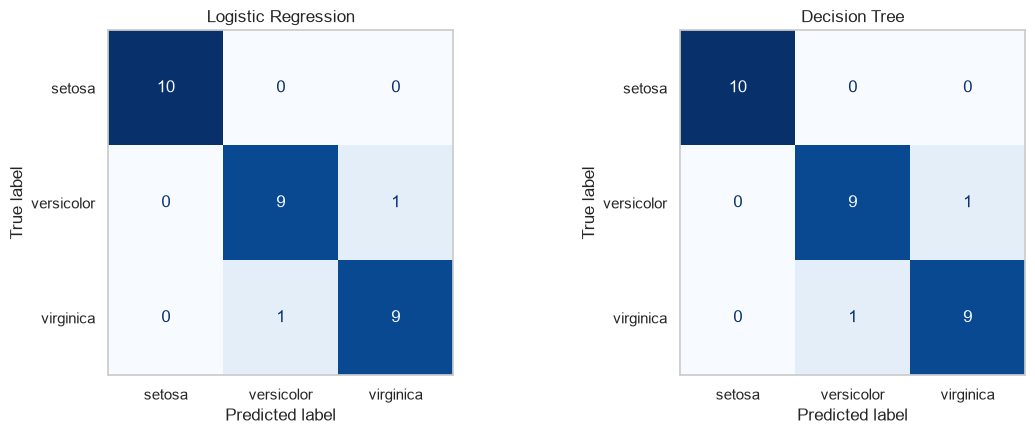

Logistic Regression


Predicted,setosa,versicolor,virginica
Actual,,,
setosa,10,0,0
versicolor,0,9,1
virginica,0,1,9


Decision Tree


Predicted,setosa,versicolor,virginica
Actual,,,
setosa,10,0,0
versicolor,0,9,1
virginica,0,1,9


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name, matrix in zip(
    axes, ["Logistic Regression", "Decision Tree"], [logistic_cm, tree_cm]
):
    ConfusionMatrixDisplay(matrix, display_labels=species_names).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": 10}
    )
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

for name, matrix in [("Logistic Regression", logistic_cm), ("Decision Tree", tree_cm)]:
    print(name)
    display(pd.DataFrame(
        matrix,
        index=pd.Index(species_names, name="Actual"),
        columns=pd.Index(species_names, name="Predicted")
    ))

## 8. Compare the models
The table below compares test accuracy and macro precision, recall, and F1-score. We also count correct predictions and inspect any mistakes. We compare full-precision values rather than rounded display values.

We rank by accuracy first, then macro F1 to break an accuracy tie. If both metrics tie, the test results do **not** identify a single better-performing model. We do not force a winner or change the split to obtain one.

In [28]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [logistic_accuracy, tree_accuracy],
    "Precision (macro)": [logistic_precision, tree_precision],
    "Recall (macro)": [logistic_recall, tree_recall],
    "F1-score (macro)": [logistic_f1, tree_f1],
    "Correct predictions": [
        int((logistic_predictions == y_test).sum()),
        int((tree_predictions == y_test).sum())
    ],
    "Test flowers": [len(y_test), len(y_test)]
}).set_index("Model")
display(comparison.round(4))

prediction_details = X_test.copy()
species_lookup = dict(enumerate(species_names))
prediction_details["Actual species"] = y_test.map(species_lookup)
prediction_details["Logistic prediction"] = pd.Series(
    logistic_predictions, index=X_test.index
).map(species_lookup)
prediction_details["Tree prediction"] = pd.Series(
    tree_predictions, index=X_test.index
).map(species_lookup)
error_rows = prediction_details.loc[
    (prediction_details["Actual species"] != prediction_details["Logistic prediction"])
    | (prediction_details["Actual species"] != prediction_details["Tree prediction"])
]
display(error_rows.sort_index())

ranked_models = comparison.sort_values(
    ["Accuracy", "F1-score (macro)"], ascending=False
)
top_scores = ranked_models.iloc[0]
top_models = comparison.index[
    (comparison["Accuracy"] == top_scores["Accuracy"])
    & (comparison["F1-score (macro)"] == top_scores["F1-score (macro)"])
].tolist()
comparison_result = (
    "Tie on test accuracy and macro F1: " + " and ".join(top_models)
    if len(top_models) > 1
    else "Better on this test split: " + top_models[0]
)
display(pd.Series({"Test-set comparison": comparison_result}).to_frame("Result"))

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Correct predictions,Test flowers
Model,,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,28,30
Decision Tree,0.9333,0.9333,0.9333,0.9333,28,30


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Actual species,Logistic prediction,Tree prediction
77,6.7,3.0,5.0,1.7,versicolor,virginica,virginica
134,6.1,2.6,5.6,1.4,virginica,versicolor,versicolor


,Result
Test-set comparison,Tie on test accuracy and macro F1: Logistic Re...


## 9. Conclusions based on the executed results
1. **Data quality:** The dataset has 150 flowers and four numeric measurements, with no missing values. Each species has 50 examples.
2. **Useful features:** Petal length and petal width show the clearest species separation. Setosa has distinctly smaller petals. Versicolor and virginica overlap, making some flowers harder to classify. Sepal measurements overlap more.
3. **Training setup:** We used 120 training flowers and 30 test flowers, with a stratified 80/20 split and `random_state=42`. Logistic Regression used a training-only scaling pipeline; the Decision Tree used the unscaled features.
4. **Actual test scores:** Both models classified **28 of 30 flowers correctly**, giving **93.33% accuracy**. Both had **0.9333 macro precision, recall, and F1-score**.
5. **Class-level results:** Each model correctly classified all 10 setosa flowers. Each confused one versicolor flower with virginica and one virginica flower with versicolor. Precision, recall, and F1 were **1.0 for setosa** and **0.9 for each of the other two species**. The two models made mistakes on the same two flowers.
6. **Which model is better?** **Neither is better on this test split: they tie on every evaluated metric.** Either is a reasonable baseline; claiming one has higher accuracy would contradict the results.
7. **Limitations:** The test set contains only 30 flowers; one prediction changes accuracy by about 3.33 percentage points. A single split does not prove which model is generally better. The harder mistakes are consistent with the overlap seen during EDA. This small, curated dataset does not represent every real-world flower or measurement condition.

### What I learned
I loaded and inspected data, explored feature relationships, prevented target leakage, split the data, trained two classifiers, and evaluated them using several metrics instead of accuracy alone.

### Possible future work (not performed here)
Use stratified cross-validation on the training data to estimate score stability and compare model settings. For further tuning, reserve a fresh final test set rather than repeatedly optimizing against the test results above.

## 10. Final checks
These checks verify data size, missingness, class balance, train/test separation, and consistency between predictions, confusion matrices, and metric calculations. If an assertion fails, it raises an error so the problem can be investigated.

To reproduce the project, restart the kernel and run all cells from top to bottom. The fixed random seed should reproduce the results in the environment recorded at the start; different library versions can sometimes change results.

In [29]:
assert X.shape == (150, 4)
assert df.shape == (150, 5)
assert not df.isna().any().any()
assert df["species"].value_counts().eq(50).all()
assert set(X_train.index).isdisjoint(X_test.index)
assert X_train.shape == (120, 4) and X_test.shape == (30, 4)
assert logistic_model.named_steps["standardscaler"].n_samples_seen_ == len(X_train)

for model_name, predictions, matrix in [
    ("Logistic Regression", logistic_predictions, logistic_cm),
    ("Decision Tree", tree_predictions, tree_cm)
]:
    assert len(predictions) == len(y_test)
    assert matrix.shape == (3, 3) and matrix.sum() == len(y_test)
    assert matrix.trace() == int((predictions == y_test).sum())
    assert comparison.loc[model_name, "Accuracy"] == accuracy_score(y_test, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions, labels=[0, 1, 2], average="macro", zero_division=0
    )
    assert comparison.loc[model_name, "Precision (macro)"] == precision
    assert comparison.loc[model_name, "Recall (macro)"] == recall
    assert comparison.loc[model_name, "F1-score (macro)"] == f1

# Check the specific results documented in the conclusions and README.
assert comparison["Correct predictions"].eq(28).all()
assert comparison["Accuracy"].eq(28 / 30).all()
assert (logistic_cm == tree_cm).all()
assert (logistic_cm == [[10, 0, 0], [0, 9, 1], [0, 1, 9]]).all()
assert len(top_models) == 2

display(pd.DataFrame({
    "Check": [
        "Data shape, missing values, and class balance",
        "Train/test separation and training-only scaling",
        "Both models and all test metrics",
        "Confusion matrices and documented results"
    ],
    "Status": ["Passed"] * 4
}))

,Check,Status
0,"Data shape, missing values, and class balance",Passed
1,Train/test separation and training-only scaling,Passed
2,Both models and all test metrics,Passed
3,Confusion matrices and documented results,Passed
